# Measure the slope, predict the wall

O-notation is not an abstraction for exams. It is the tool that tells you, from
a run on a small sample, whether your script will finish on the full data. This
notebook measures three solutions of the same problem, reads their growth rates
off a plot, and extrapolates to data sizes you will meet. It ends with the
difference between best, average and worst case on one and the same code.

## 1. Three ways to find duplicate ids

A survey file should have one row per respondent, but ids repeat. We find the
duplicates three ways: compare every pair, sort and compare neighbors, or keep a
set of ids seen so far. Same answer, different work.

In [1]:
import random, time

def duplicates_pairs(ids):                       # compare every pair
    dup = set()
    for i in range(len(ids)):
        for j in range(i + 1, len(ids)):
            if ids[i] == ids[j]:
                dup.add(ids[i])
    return dup

def duplicates_sorted(ids):                      # sort, then look at neighbors
    s = sorted(ids)
    return {s[i] for i in range(1, len(s)) if s[i] == s[i - 1]}

def duplicates_set(ids):                         # one pass with a hash set
    seen, dup = set(), set()
    for x in ids:
        (dup if x in seen else seen).add(x)
    return dup

rnd = random.Random(8)
ns = [500, 1000, 2000, 4000]
times = {"every pair": [], "sort and scan": [], "hash set": []}
for n in ns:
    ids = [rnd.randrange(n * 10) for _ in range(n)]
    for name, f in zip(times, [duplicates_pairs, duplicates_sorted, duplicates_set]):
        t0 = time.perf_counter(); f(ids); times[name].append(time.perf_counter() - t0)
    print(f"n = {n:5}   " + "   ".join(f"{k}: {v[-1]:9.5f} s" for k, v in times.items()))

n =   500   every pair:   0.00525 s   sort and scan:   0.00010 s   hash set:   0.00006 s
n =  1000   every pair:   0.02040 s   sort and scan:   0.00020 s   hash set:   0.00010 s
n =  2000   every pair:   0.09014 s   sort and scan:   0.00068 s   hash set:   0.00028 s


n =  4000   every pair:   0.39802 s   sort and scan:   0.00118 s   hash set:   0.00044 s


## 2. Read the exponent off the plot

If the running time is $c \cdot n^k$, then $\log t = \log c + k \log n$: on a
log-log plot the points lie on a line of slope $k$. We fit that slope to the
measurements. The exponent is the number to remember; the constant $c$ depends
on the machine and the exponent does not.

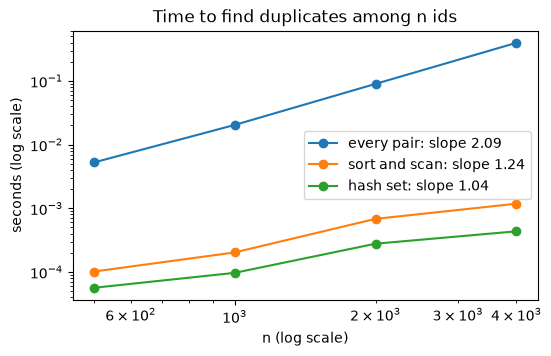

In [2]:
import numpy as np
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(6, 3.5))
slopes = {}
for name, t in times.items():
    k, logc = np.polyfit(np.log(ns), np.log(t), 1)
    slopes[name] = (k, np.exp(logc))
    ax.plot(ns, t, "o-", label=f"{name}: slope {k:.2f}")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("n (log scale)"); ax.set_ylabel("seconds (log scale)"); ax.legend()
ax.set_title("Time to find duplicates among n ids")
plt.show()

The pairwise version has slope close to 2, the other two close to 1 (the sort is
$n \log n$, whose slope on this range is only slightly above 1). Now the
extrapolation. We use the fitted line to predict the running time for the sizes
of real data sets: a million rows, ten million, a billion.

In [3]:
def human(seconds):
    for unit, size in [("years", 3.15e7), ("days", 86400), ("hours", 3600), ("min", 60)]:
        if seconds >= size:
            return f"{seconds / size:,.1f} {unit}"
    return f"{seconds:.2f} s"

print(f"{'n':>15}" + "".join(f"{name:>18}" for name in times))
for n in [10**6, 10**7, 10**9]:
    row = f"{n:>15,}"
    for name, (k, c) in slopes.items():
        row += f"{human(c * n ** k):>18}"
    print(row)

              n        every pair     sort and scan          hash set
      1,000,000        11.0 hours            1.21 s            0.14 s
     10,000,000         55.9 days           20.86 s            1.57 s
  1,000,000,000     2,298.0 years         1.7 hours           3.1 min


The pairwise comparison, which took a quarter of a second on four thousand
rows, needs hours on a million rows, more than a week on ten million and more
than a century on a billion. The other two finish in seconds. No faster computer changes the first
column into the third: a hundred times faster hardware divides every entry by a
hundred, and years divided by a hundred are still years. The exponent decides
what is feasible, the hardware decides how comfortably.

This is why the lecture insists on the worst-case growth rate and not on
measured seconds. The seconds were measured on a sample, and the sample is
always small.

## 3. The same code, three running times

Complexity depends on the input, not only on the code. A linear search for a
value in a list stops as soon as it finds it. We search a list of a hundred
thousand ids for a value that sits at the front, for random values that are in
the list, and for values that are not, and time each case.

In [4]:
ids = list(range(100_000))
rnd.shuffle(ids)

def linear_search(A, x):
    for i, a in enumerate(A):
        if a == x:
            return i
    return -1

def average_time(queries):
    t0 = time.perf_counter()
    for q in queries: linear_search(ids, q)
    return (time.perf_counter() - t0) / len(queries)

best = average_time([ids[0]] * 200)                              # the value is the first element
average = average_time([rnd.choice(ids) for _ in range(200)])     # a random value that is present
worst = average_time([-1] * 200)                                  # a value that is absent
print(f"best case    (value is first):    {best * 1e6:9.1f} microseconds")
print(f"average case (random present):    {average * 1e6:9.1f} microseconds")
print(f"worst case   (value is absent):   {worst * 1e6:9.1f} microseconds")

best case    (value is first):          0.4 microseconds
average case (random present):       4757.9 microseconds
worst case   (value is absent):      8964.7 microseconds


The best case does not depend on $n$ at all, $O(1)$; the average case looks at
about half the list; the worst case looks at all of it, $O(n)$. When you report
the complexity of an algorithm you report the worst case unless you say
otherwise, because the worst case is what a user hits when the data is
unlucky, and a search for something that is not there is not unlucky at all,
it is the most common query in a cleaning script.

**What we used:** why complexity matters, with numbers
([session 8, section 3](../Transcripts/08-TimeComplexity.md#3-why-it-matters-some-numbers)),
runtime analysis ([section 4](../Transcripts/08-TimeComplexity.md#4-runtime-analysis)),
best, average and worst case ([section 5](../Transcripts/08-TimeComplexity.md#5-best-average-and-worst-case)),
O-notation ([sections 8 and 9](../Transcripts/08-TimeComplexity.md#8-asymptotic-behavior-and-o-notation)),
and hash sets from [session 3, section 8](../Transcripts/03-DataStructures.md#8-hashing-and-hash-tables).